# Corridor home-origin activity, interpolated onto Oakland block groups

For each corridor and each time period, this notebook answers: **of the people who visit this corridor, what
share live in each Oakland block group?** The result is what the map paints when a corridor is selected and
one of the Activity layers (All / Evenings / Daytime / Weekdays / Weekends) is on.

Pipeline:

1. Load the half-year home table (`corridor_homes`): device-months by corridor x period x **home block group
   (2010 vintage)**. Devices with no matched Bay Area home are dropped (they are not "from" anywhere we can map).
2. **Exclude provider segment S2** (Jan-Jun 2023): its home panel is only ~17k devices, so a corridor has a few
   hundred device-months in it, and it is only 0.3% of the pooled total anyway.
3. Split each home block group onto the 2020 Oakland block groups with the **population-weighted crosswalk**
   from `02_`.
4. Convert to **% share of the corridor's total matched-home activity, separately for each provider segment (S1 and S3)**.
5. **Combine S1 and S3 with explicit equal weights.** Adjusted counts are scaled to each segment's own panel, so
   pooling raw counts would let whichever segment has the larger numbers dominate for an arbitrary reason. Averaging
   two within-segment *shares* gives each provider the same say, and no calibration across providers is needed
   (shares are computed inside a provider). `04_cross_segment_comparability` tests whether the two segments
   agree well enough for this to be reasonable.
6. Roll the same allocation up to **council districts**, per segment and pooled.
7. Write one small JSON file per corridor for the front end, plus quintile legend breaks.

The denominator for every share *includes* visitors from outside Oakland (San Francisco, the rest of the East
Bay ...), so the Oakland shares sum to less than 100% and the gap is itself a finding ("how local is this corridor?").

**Why percent shares?** The mobility data licence does not allow publishing raw counts, and shares are what
the TAC map uses too. **Which measure.** `normalized_unique_device_months` (devices counted once per month they
appear, re-weighted for home-sample size), as in the TAC map.

---

| | |
|---|---|
| **Inputs** | `data/activity/processed/corridor_homes.csv.gz`, `home_geography.csv.gz`, `corridor_lookup.csv` (from `01_`)<br>`bg_crosswalk_2010_to_2020.csv.gz`, `bg_district_weights.csv`, `corridor_districts.csv` (from `02_`) |
| **Outputs** | `src/data/activity/corridor_home_origin/corridor_<slug>.json` (21 files; BG GEOID -> % share per period, S1/S3 equal-weighted)<br>`src/data/activity/legend_breaks.json` (quintile breaks per period; paste into `src/lib/maps/LayerConfig.js`)<br>`data/activity/processed/corridor_bg_origin.csv.gz`, `corridor_bg_origin_by_segment.csv.gz`, `corridor_district_origin.csv`, `corridor_district_origin_by_segment.csv` |
| **Run after** | `01_combine_corridor_results.ipynb`, `02_bg_crosswalk_and_districts.ipynb` |

In [1]:
import json
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", message="Unable to import Axes3D")

/home/aniket/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# --- Paths ---
# Repo root = nearest parent folder containing package.json, so this notebook runs from any depth.
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "package.json").exists())
DATA = ROOT / "data"                 # raw + intermediate files
SRC_DATA = ROOT / "src" / "data"     # final outputs consumed directly by the web app
PROCESSED_DIR = DATA / "activity" / "processed"

HOMES_CSV = PROCESSED_DIR / "corridor_homes.csv.gz"
HOME_GEOGRAPHY_CSV = PROCESSED_DIR / "home_geography.csv.gz"
CORRIDOR_LOOKUP_CSV = PROCESSED_DIR / "corridor_lookup.csv"
CROSSWALK_CSV = PROCESSED_DIR / "bg_crosswalk_2010_to_2020.csv.gz"
BG_DISTRICT_CSV = PROCESSED_DIR / "bg_district_weights.csv"
CORRIDOR_DISTRICT_CSV = PROCESSED_DIR / "corridor_districts.csv"
OAK_BG_GEOJSON = SRC_DATA / "OAK_BG.geo.json"

# Final outputs: bundled into the web app, lazy-loaded one corridor at a time
ACTIVITY_OUT_DIR = SRC_DATA / "activity"
ORIGIN_OUT_DIR = ACTIVITY_OUT_DIR / "corridor_home_origin"            # S1/S3 equal-weighted (default)
ORIGIN_OUT_DIR_BY_SEGMENT = {"S1": ACTIVITY_OUT_DIR / "corridor_home_origin_s1", "S3": ACTIVITY_OUT_DIR / "corridor_home_origin_s3"}
LEGEND_BREAKS_JSON = ACTIVITY_OUT_DIR / "legend_breaks.json"
# Intermediates for the next notebooks
BG_ORIGIN_CSV = PROCESSED_DIR / "corridor_bg_origin.csv.gz"                    # S1/S3 equal-weighted
BG_ORIGIN_SEGMENT_CSV = PROCESSED_DIR / "corridor_bg_origin_by_segment.csv.gz"  # one set of shares per segment
DISTRICT_ORIGIN_CSV = PROCESSED_DIR / "corridor_district_origin.csv"
DISTRICT_ORIGIN_SEGMENT_CSV = PROCESSED_DIR / "corridor_district_origin_by_segment.csv"

# --- Parameters ---
TIME_PERIODS = ["all", "evening", "nine-five", "weekdays", "weekends"]   # same keys as the Activity layers in LayerConfig.js
VALUE_COL = "normalized_unique_device_months"
UNMATCHED_BG = "UNKNOWN"          # block_group_id for devices with no matched Bay Area home

# Provider segments used for origin shares, and the weight each gets when they are combined.
# Equal weights on purpose: see the notes at the top of this notebook.
SEGMENT_WEIGHTS = {"S1_LIMA": 0.5, "S3_PAPA": 0.5}
EXCLUDED_SEGMENTS = {"S2_SIERRA": "Jan-Jun 2023, ~17k-device home panel: a few hundred device-months per corridor"}
INCLUDE_HALF_YEARS = None         # None = every half-year of the included segments; or a list like ["2024H1", "2024H2"]

ROUND_DECIMALS = 4                # precision of the published % shares
QUINTILE_PERCENTILES = [20, 40, 60, 80]

# --- Chart styling (see dataviz skill: fixed categorical order, single-hue sequential) ---
CATEGORICAL_PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQUENTIAL_BLUE_RAMP = ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95"]
CHART_GRID_COLOR = "#e1e0d9"
CHART_MUTED_TEXT = "#898781"
MAP_BASE = "#eceae3"

In [3]:
def style_axis(ax, grid_axis="y"):
    """Shared cosmetic cleanup: recessive grid, no top/right spines."""
    ax.grid(axis=grid_axis, color=CHART_GRID_COLOR, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.tick_params(colors=CHART_MUTED_TEXT)


def seg_id(provider_segment):
    """'S1_LIMA' -> 'S1' (provider names are not published)."""
    return provider_segment.split("_")[0]


def pool_segments(df, keys, value, present=None, group_keys=("corridor_slug", "time_period"), seg_col="segment", weights=None):
    """Weighted combination of per-segment values.

    `df` has one row per (keys..., segment). A key that is absent from a segment counts as 0 for that segment *as long as the
    segment has data for the group* (`present` lists the (group_keys..., segment) combinations that exist; default = `df`).
    The weights are renormalised over the segments present in each group, so a corridor-period with data in only one
    segment still gets a valid value.
    """
    weights = weights or {seg_id(k): v for k, v in SEGMENT_WEIGHTS.items()}
    group_keys = list(group_keys)
    present = df if present is None else present
    w_present = present.assign(w=present[seg_col].map(weights)).groupby(group_keys, as_index=False).w.sum().rename(columns={"w": "w_sum"})
    tmp = df[keys].copy()
    tmp["wv"] = df[value] * df[seg_col].map(weights)
    out = tmp.groupby(keys, as_index=False).wv.sum().merge(w_present, on=group_keys)
    out[value] = out.wv / out.w_sum
    return out[keys + [value]]

## Load the home table

`corridor_homes` has ~2.4M rows (corridor x half-year x period x home block group). S2 rows are dropped first;
device-months of unmatched homes (`UNKNOWN`) are separated out so we can report how much activity is excluded.

In [4]:
homes = pd.read_csv(HOMES_CSV, dtype={"block_group_id": str})
lookup = pd.read_csv(CORRIDOR_LOOKUP_CSV)
home_geo = pd.read_csv(HOME_GEOGRAPHY_CSV, dtype={"geoid": str})
home_geo["geoid"] = home_geo["geoid"].str.zfill(12)

n_all = len(homes)
excluded = homes[homes.provider_segment.isin(EXCLUDED_SEGMENTS)]
homes = homes[homes.provider_segment.isin(SEGMENT_WEIGHTS)]
if INCLUDE_HALF_YEARS is not None:
    homes = homes[homes.half_year.isin(INCLUDE_HALF_YEARS)]
print(f"Excluded {len(excluded):,} of {n_all:,} rows from {sorted(excluded.provider_segment.unique())}: {EXCLUDED_SEGMENTS}")
print(f"{len(homes):,} rows kept; half-years: {sorted(homes.half_year.unique())}")

# unmatched share: UNKNOWN rows have no normalised value, so use raw device-months to size them
raw_total = homes.groupby(["provider_segment", "time_period"]).unique_device_months.sum()
raw_unmatched = homes[homes.block_group_id == UNMATCHED_BG].groupby(["provider_segment", "time_period"]).unique_device_months.sum()
print("\nShare of raw device-months with no matched Bay Area home (excluded from every share below):")
display((raw_unmatched / raw_total * 100).round(1).unstack("time_period")[TIME_PERIODS])

homes = homes[homes.block_group_id != UNMATCHED_BG].merge(
    home_geo[["block_group_id", "geoid"]], on="block_group_id", how="left", validate="many_to_one"
)
homes["segment"] = homes.provider_segment.map(seg_id)
assert homes.geoid.notna().all(), "home block group missing from home_geography"
assert homes[VALUE_COL].notna().all()

Excluded 20,340 of 2,426,581 rows from ['S2_SIERRA']: {'S2_SIERRA': 'Jan-Jun 2023, ~17k-device home panel: a few hundred device-months per corridor'}
2,406,241 rows kept; half-years: ['2019H1', '2019H2', '2020H1', '2020H2', '2021H1', '2021H2', '2022H1', '2022H2', '2023H2', '2024H1', '2024H2', '2025H1', '2025H2']



Share of raw device-months with no matched Bay Area home (excluded from every share below):


time_period,all,evening,nine-five,weekdays,weekends
provider_segment,,,,,
S1_LIMA,22.4,22.4,19.4,21.1,21.6
S3_PAPA,58.4,57.5,53.7,57.7,55.6


The matched-home rate is clearly lower in S3 than S1. That is one reason shares from the two segments are never mixed
at the *count* level, only combined after each is expressed as a share of its own total.

## Aggregate to corridor x period x segment x home block group

Summing across the half-years of a segment gives one number per (corridor, period, segment, home block group).
The **denominator** for every share is that corridor-period-segment's total across *all* matched homes, wherever
they are.

In [5]:
agg = homes.groupby(["corridor_slug", "time_period", "segment", "geoid"], as_index=False)[VALUE_COL].sum()
seg_totals = agg.groupby(["corridor_slug", "time_period", "segment"])[VALUE_COL].sum().rename("total_matched").reset_index()

print(f"{len(agg):,} corridor x period x segment x home-BG rows; {agg.geoid.nunique():,} distinct home block groups")
display(seg_totals[seg_totals.time_period == "all"].pivot(index="corridor_slug", columns="segment", values="total_matched").round(0).astype(int).head(5))

687,454 corridor x period x segment x home-BG rows; 4,753 distinct home block groups


segment,S1,S3
corridor_slug,,
7th_st_thrives,45996,61270
bambd,69528,175272
chinatown,169983,169059
dimond,46493,37543
downtown,153877,201593


## Interpolate onto Oakland block groups

Join the crosswalk (`src_geoid` -> `tgt_geoid`, weight) and allocate. Rows whose home block group does not touch
Oakland at all (most of the Bay Area) drop out of the *numerator* but stay in the *denominator*.

In [6]:
crosswalk = pd.read_csv(CROSSWALK_CSV, dtype={"src_geoid": str, "tgt_geoid": str})

alloc = agg.merge(crosswalk, left_on="geoid", right_on="src_geoid", how="inner")
alloc["allocated"] = alloc[VALUE_COL] * alloc["weight"]

bg_seg = alloc.groupby(["corridor_slug", "time_period", "segment", "tgt_geoid"], as_index=False)["allocated"].sum()
bg_seg = bg_seg.merge(seg_totals, on=["corridor_slug", "time_period", "segment"])
bg_seg["pct_share"] = bg_seg["allocated"] / bg_seg["total_matched"] * 100
bg_seg = bg_seg.rename(columns={"tgt_geoid": "bg_geoid"})[["corridor_slug", "time_period", "segment", "bg_geoid", "pct_share"]]
bg_seg.to_csv(BG_ORIGIN_SEGMENT_CSV, index=False)

# equal-weight combination of the two segments' shares
bg_origin = pool_segments(bg_seg, ["corridor_slug", "time_period", "bg_geoid"], "pct_share", present=seg_totals)
bg_origin.to_csv(BG_ORIGIN_CSV, index=False)
print(f"{len(bg_seg):,} per-segment rows -> {len(bg_origin):,} pooled corridor x period x Oakland-BG rows")

oak_by_seg = bg_seg[bg_seg.time_period == "all"].groupby(["corridor_slug", "segment"]).pct_share.sum().unstack("segment")
oakland_share = bg_origin.groupby(["corridor_slug", "time_period"]).pct_share.sum().unstack("time_period")[TIME_PERIODS]
print("\n% of each corridor's matched-home activity that lands on an Oakland block group (period = all):")
display(pd.concat([oak_by_seg.add_prefix("Oakland % "), oakland_share["all"].rename("pooled")], axis=1).sort_values("pooled").round(1).T)

73,428 per-segment rows -> 37,087 pooled corridor x period x Oakland-BG rows

% of each corridor's matched-home activity that lands on an Oakland block group (period = all):


corridor_slug,uptown_arts_and_entertainment_district,jack_london,hegenberger,chinatown,downtown,temescal_telegraph,lake_merritt,old_oakland,rockridge,7th_st_thrives,...,northlake,bambd,little_saigon,fruitvale,elmhurst,montclair,lakeshore,havencourt,dimond,laurel
Oakland % S1,25.8,27.9,26.7,29.4,28.7,31.3,31.0,31.1,36.0,31.9,...,35.3,35.1,49.0,57.4,59.1,57.5,58.0,60.7,68.1,69.0
Oakland % S3,34.4,36.5,39.7,38.6,40.9,41.0,42.7,44.0,40.0,46.9,...,49.1,50.3,56.6,52.7,54.8,56.8,59.1,64.9,66.1,67.3
pooled,30.1,32.2,33.2,34.0,34.8,36.2,36.9,37.5,38.0,39.4,...,42.2,42.7,52.8,55.0,56.9,57.2,58.5,62.8,67.1,68.2


The Oakland share is about **10 points higher in S3 than S1** for most corridors. We do not read that as
"visitors became more local": the provider (and its home-matching) changed. It is one of the reasons shares are
kept per segment for the profile panel and only combined, with explicit equal weights, for the map.
`04_cross_segment_comparability` quantifies which metrics can be compared across the break.

### Cross-check against the data's own 'Oakland' label

`corridor_homes` already labels each home block group (`Oakland`, `San Francisco`, `Rest East Bay`,
`Rest Bay Area`). The interpolated Oakland share should match the labelled one closely. Small gaps are expected:
the label is assigned from the block group's internal point, while the interpolation follows area overlap and the
2020 map boundaries.

Max absolute gap across corridors and periods: 0.04 percentage points


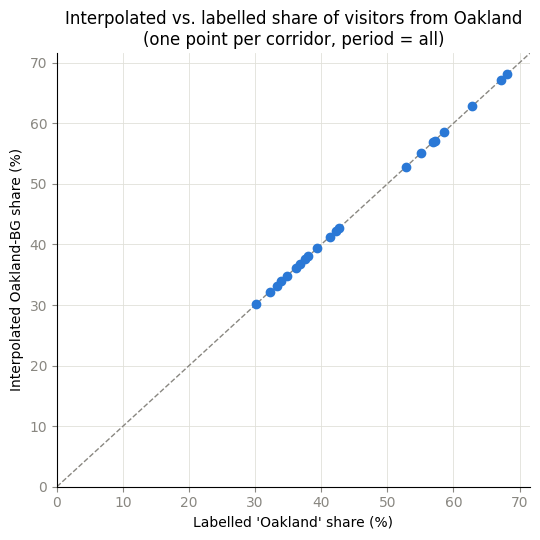

In [7]:
lab = homes.assign(is_oakland=homes.home_geography == "Oakland").groupby(["corridor_slug", "time_period", "segment", "is_oakland"])[VALUE_COL].sum().unstack("is_oakland").fillna(0)
lab = (lab[True] / lab.sum(axis=1) * 100).rename("labelled").reset_index()
labelled_pooled = pool_segments(lab, ["corridor_slug", "time_period"], "labelled").pivot(index="corridor_slug", columns="time_period", values="labelled")[TIME_PERIODS]

compare = pd.DataFrame({"interpolated": oakland_share["all"], "labelled": labelled_pooled["all"]})
compare["diff_pts"] = compare.interpolated - compare.labelled
print(f"Max absolute gap across corridors and periods: {(oakland_share - labelled_pooled).abs().max().max():.2f} percentage points")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(compare.labelled, compare.interpolated, color=CATEGORICAL_PALETTE[0], s=36, zorder=3)
lim = [0, max(compare.max()[:2]) * 1.05]
ax.plot(lim, lim, color=CHART_MUTED_TEXT, linewidth=1, linestyle="--", zorder=2)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Labelled 'Oakland' share (%)")
ax.set_ylabel("Interpolated Oakland-BG share (%)")
ax.set_title("Interpolated vs. labelled share of visitors from Oakland\n(one point per corridor, period = all)")
style_axis(ax, "both")
plt.tight_layout()
plt.show()

## Council-district origin

The same Oakland-BG allocation is split across council districts using the block-group -> district area
weights (`bg_district_weights.csv`), per segment and pooled. For each corridor and period this gives the share of
visitors living in each of the seven districts; whatever is not in a district is "outside Oakland".

**"Origin inside the corridor's own district"** = the share from the corridor's *primary* district (the one
holding most of its area). The full seven-district vector is kept too, so a corridor that straddles two districts
(e.g. Downtown, which sits in districts 2 and 3) can be read either way.

In [8]:
bg_district = pd.read_csv(BG_DISTRICT_CSV, dtype={"bg_geoid": str})
corridor_districts = pd.read_csv(CORRIDOR_DISTRICT_CSV)
districts = sorted(bg_district.district.unique())


def to_districts(bg_df, extra_keys=()):
    keys = ["corridor_slug", "time_period", *extra_keys]
    d = bg_df.merge(bg_district, on="bg_geoid", how="inner")
    d["pct"] = d.pct_share * d.weight
    d = d.groupby(keys + ["district"], as_index=False).pct.sum()
    full = pd.MultiIndex.from_product(
        [lookup.corridor_slug, TIME_PERIODS] + [sorted(bg_df[k].unique()) for k in extra_keys] + [districts],
        names=["corridor_slug", "time_period", *extra_keys, "district"],
    )
    return d.set_index(keys + ["district"]).reindex(full, fill_value=0.0).reset_index()


dist_seg = to_districts(bg_seg, extra_keys=("segment",))
dist_origin = to_districts(bg_origin)
dist_seg.to_csv(DISTRICT_ORIGIN_SEGMENT_CSV, index=False)
dist_origin.to_csv(DISTRICT_ORIGIN_CSV, index=False)

primary = corridor_districts.set_index("corridor_slug")["primary_district"]
in_district = (
    dist_origin[dist_origin.district == dist_origin.corridor_slug.map(primary)]
    .set_index(["corridor_slug", "time_period"]).pct.unstack("time_period")[TIME_PERIODS]
)
in_district.insert(0, "primary_district", primary)
display(in_district.round(1).sort_values("all", ascending=False))

time_period,primary_district,all,evening,nine-five,weekdays,weekends
corridor_slug,,,,,,
elmhurst,7,30.7,36.5,32.9,32.1,35.9
montclair,4,29.4,34.9,32.3,31.1,33.9
havencourt,6,28.9,37.3,29.7,30.1,35.0
laurel,4,23.5,27.0,24.3,24.2,26.8
little_saigon,2,21.6,29.7,22.1,23.0,24.9
fruitvale,5,19.8,25.3,22.2,21.7,23.5
7th_st_thrives,3,19.7,24.6,21.8,20.9,24.7
bambd,3,19.5,26.0,19.5,20.5,24.6
northlake,3,19.1,25.8,19.7,20.4,24.2


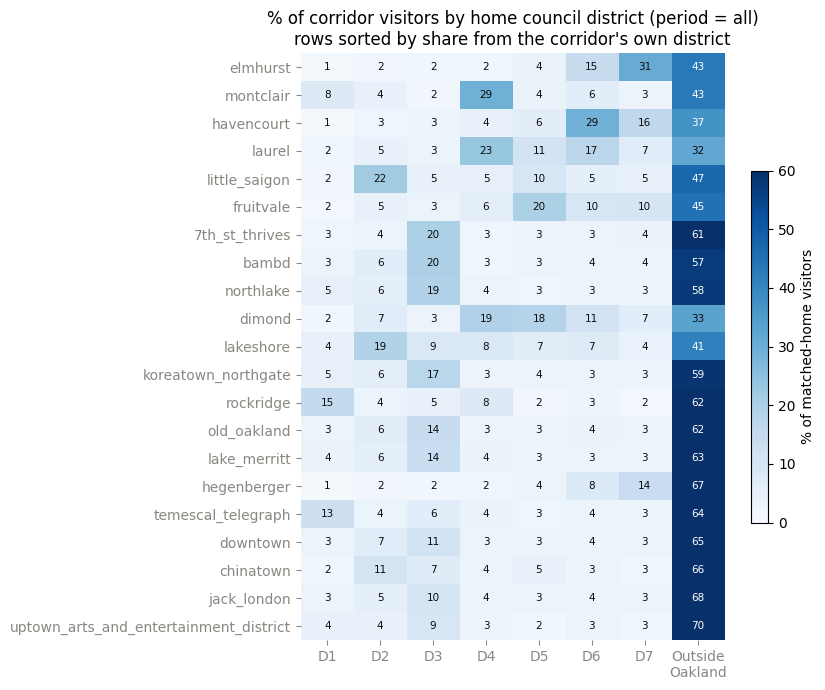

In [9]:
# Heatmap: where do each corridor's visitors live, by council district? (period = all, S1/S3 equal-weighted)
mat = dist_origin[dist_origin.time_period == "all"].pivot(index="corridor_slug", columns="district", values="pct")
mat["outside"] = 100 - mat.sum(axis=1)
mat = mat.loc[in_district.sort_values("all", ascending=False).index]

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(mat.values, cmap=plt.cm.Blues, aspect="auto", vmin=0, vmax=60)
ax.set_xticks(range(mat.shape[1]), [f"D{c}" if c != "outside" else "Outside\nOakland" for c in mat.columns])
ax.set_yticks(range(mat.shape[0]), mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5, color="white" if v > 35 else "#0b0b0b")
ax.set_title("% of corridor visitors by home council district (period = all)\nrows sorted by share from the corridor's own district")
ax.tick_params(colors=CHART_MUTED_TEXT)
for s in ax.spines.values():
    s.set_visible(False)
plt.colorbar(im, ax=ax, shrink=0.6, label="% of matched-home visitors")
plt.tight_layout()
plt.show()

## Legend breaks (quintiles)

Same approach as the Toronto map: **quintile breakpoints (20/40/60/80th percentile)** of every *nonzero* share,
pooled over all corridors, separately for each period. Zero shares are excluded; most block groups send nobody
to a given corridor, and including those zeros would collapse the low breakpoints to ~0. On the map, zero/no-data
block groups use the neutral grey, and the five-colour ramp is reserved for block groups that actually contribute
visitors.

Quintile breakpoints (% share, nonzero only), written to src/data/activity/legend_breaks.json
  [pooled]
           all: [0.033, 0.058, 0.09, 0.155]
       evening: [0.029, 0.056, 0.09, 0.164]
     nine-five: [0.03, 0.056, 0.091, 0.164]
      weekdays: [0.033, 0.059, 0.091, 0.16]
      weekends: [0.029, 0.052, 0.087, 0.161]
  [S1]
           all: [0.031, 0.057, 0.089, 0.156]
       evening: [0.028, 0.056, 0.092, 0.173]
     nine-five: [0.029, 0.056, 0.093, 0.169]
      weekdays: [0.031, 0.058, 0.092, 0.163]
      weekends: [0.026, 0.051, 0.087, 0.166]
  [S3]
           all: [0.03, 0.054, 0.087, 0.158]
       evening: [0.026, 0.05, 0.085, 0.163]
     nine-five: [0.027, 0.052, 0.088, 0.167]
      weekdays: [0.029, 0.053, 0.087, 0.161]
      weekends: [0.026, 0.049, 0.085, 0.159]


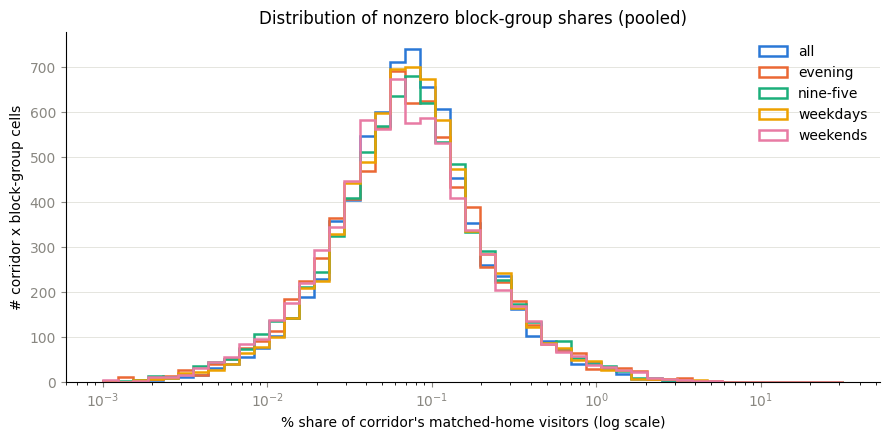

In [10]:
variants = {"pooled": bg_origin, **{seg: bg_seg[bg_seg.segment == seg] for seg in ["S1", "S3"]}}
legend_breaks = {}
for name, df in variants.items():
    legend_breaks[name] = {}
    for period in TIME_PERIODS:
        nonzero = df.loc[(df.time_period == period) & (df.pct_share > 0), "pct_share"]
        legend_breaks[name][period] = [round(float(v), 3) for v in np.percentile(nonzero, QUINTILE_PERCENTILES)]

ACTIVITY_OUT_DIR.mkdir(parents=True, exist_ok=True)
with open(LEGEND_BREAKS_JSON, "w") as f:
    json.dump(legend_breaks, f, indent=2)

print("Quintile breakpoints (% share, nonzero only), written to", LEGEND_BREAKS_JSON.relative_to(ROOT))
for name, per_period in legend_breaks.items():
    print(f"  [{name}]")
    for period, brk in per_period.items():
        print(f"    {period:>10}: {brk}")

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.logspace(-3, 1.5, 50)
for color, period in zip(CATEGORICAL_PALETTE, TIME_PERIODS):
    vals = bg_origin.loc[(bg_origin.time_period == period) & (bg_origin.pct_share > 0), "pct_share"]
    ax.hist(vals, bins=bins, histtype="step", linewidth=1.8, color=color, label=period)
ax.set_xscale("log")
ax.set_xlabel("% share of corridor's matched-home visitors (log scale)")
ax.set_ylabel("# corridor x block-group cells")
ax.set_title("Distribution of nonzero block-group shares (pooled)")
ax.legend(frameon=False)
style_axis(ax)
plt.tight_layout()
plt.show()

## Write per-corridor JSON for the front end

One file per corridor: `corridor_<slug>.json`, an object keyed by block-group **GEOID** (the map's feature id,
`promoteId: "GEOID"`) holding that block group's % share for each period (S1 and S3 equal-weighted). The period
keys match the Activity layer `key`s in `LayerConfig.js` (`all`, `evening`, `nine-five`, `weekdays`, `weekends`),
so the file can be passed straight to `map.setFeatureState`.

To keep files small and fast to parse: **sparse** (zero shares omitted; the map paints a missing value in the same
neutral grey as a true zero), **minified**, and shares rounded to 4 decimals of a percent.

In [11]:
def write_corridor_files(df, out_dir):
    """One minified, sparse JSON per corridor: {GEOID: {period: % share}}."""
    out_dir.mkdir(parents=True, exist_ok=True)
    for stale in out_dir.glob("corridor_*.json"):      # remove stale files from earlier runs (e.g. a renamed corridor)
        stale.unlink()
    wide = df.pivot_table(index=["corridor_slug", "bg_geoid"], columns="time_period", values="pct_share")
    wide = wide.reindex(columns=TIME_PERIODS).round(ROUND_DECIMALS)
    records = {}
    for slug, grp in tqdm(wide.groupby(level="corridor_slug"), desc=f"writing {out_dir.name}"):
        grp = grp.droplevel("corridor_slug")
        record = {}
        for geoid, row in grp.iterrows():
            vals = {p: float(v) for p, v in row.items() if pd.notna(v) and v > 0}
            if vals:
                record[geoid] = vals
        records[slug] = record
        with open(out_dir / f"corridor_{slug}.json", "w") as f:
            json.dump(record, f, separators=(",", ":"))
    return records


records = write_corridor_files(bg_origin, ORIGIN_OUT_DIR)
segment_records = {seg: write_corridor_files(bg_seg[bg_seg.segment == seg], out_dir) for seg, out_dir in ORIGIN_OUT_DIR_BY_SEGMENT.items()}

sizes = pd.Series({s: (ORIGIN_OUT_DIR / f"corridor_{s}.json").stat().st_size for s in records})
n_bgs = pd.Series({s: len(r) for s, r in records.items()})
total_kb = sum(p.stat().st_size for d in [ORIGIN_OUT_DIR, *ORIGIN_OUT_DIR_BY_SEGMENT.values()] for p in d.glob("*.json")) / 1024
print(f"Wrote {len(records)} corridors x 3 variants (pooled, S1, S3): {total_kb:.0f} KB total; "
      f"pooled files avg {sizes.mean() / 1024:.1f} KB (max {sizes.max() / 1024:.1f} KB), one corridor loaded at a time")
print(f"Block groups with data per corridor: min {n_bgs.min()}, median {int(n_bgs.median())}, max {n_bgs.max()} of 354")

writing corridor_home_origin:   0%|          | 0/21 [00:00<?, ?it/s]

writing corridor_home_origin_s1:   0%|          | 0/21 [00:00<?, ?it/s]

writing corridor_home_origin_s3:   0%|          | 0/21 [00:00<?, ?it/s]

Wrote 21 corridors x 3 variants (pooled, S1, S3): 2190 KB total; pooled files avg 35.0 KB (max 35.1 KB), one corridor loaded at a time
Block groups with data per corridor: min 353, median 354, max 354 of 354


In [12]:
# Sanity checks on the written files
example = json.load(open(ORIGIN_OUT_DIR / "corridor_downtown.json"))
print("corridor_downtown.json (first 2 block groups):")
print(json.dumps(dict(list(example.items())[:2]), indent=2))

oak_ids = set(gpd.read_file(OAK_BG_GEOJSON).GEOID)
bad_keys = {g for r in records.values() for g in r} - oak_ids
print(f"\nGEOIDs in output that are not on the map: {len(bad_keys)}")
assert not bad_keys

sums = pd.DataFrame({s: {p: sum(v.get(p, 0) for v in r.values()) for p in TIME_PERIODS} for s, r in records.items()}).T
print(f"Sum of shares per corridor x period: min {sums.min().min():.1f}%, max {sums.max().max():.1f}% (must be <= 100)")
assert sums.max().max() <= 100.01

corridor_downtown.json (first 2 block groups):
{
  "060014001001": {
    "all": 0.118,
    "evening": 0.1453,
    "nine-five": 0.1224,
    "weekdays": 0.1221,
    "weekends": 0.108
  },
  "060014001002": {
    "all": 0.0588,
    "evening": 0.0724,
    "nine-five": 0.061,
    "weekdays": 0.0608,
    "weekends": 0.0538
  }
}



GEOIDs in output that are not on the map: 0
Sum of shares per corridor x period: min 29.0%, max 72.6% (must be <= 100)


## Visual check

Small maps of the Oakland block-group shares for four corridors (period = all, quintile colours from the
legend breaks above), with the corridor outlined. A good-looking result has the colours decaying outward from the
corridor and from its neighbouring block groups, with a long tail of faint, far-away block groups.

**One visual caveat for the front end:** the layer shows each block group's *share* of the corridor's visitors, so
physically large block groups (the waterfront/port area in the west, the hills in the north) look dark simply
because they hold many residents' worth of area. A per-resident or per-km2 version would emphasise intensity
instead; the shares written here can be divided by `pop_count` or `area_sqkm` in `OAK_BG.geo.json` if that is wanted.

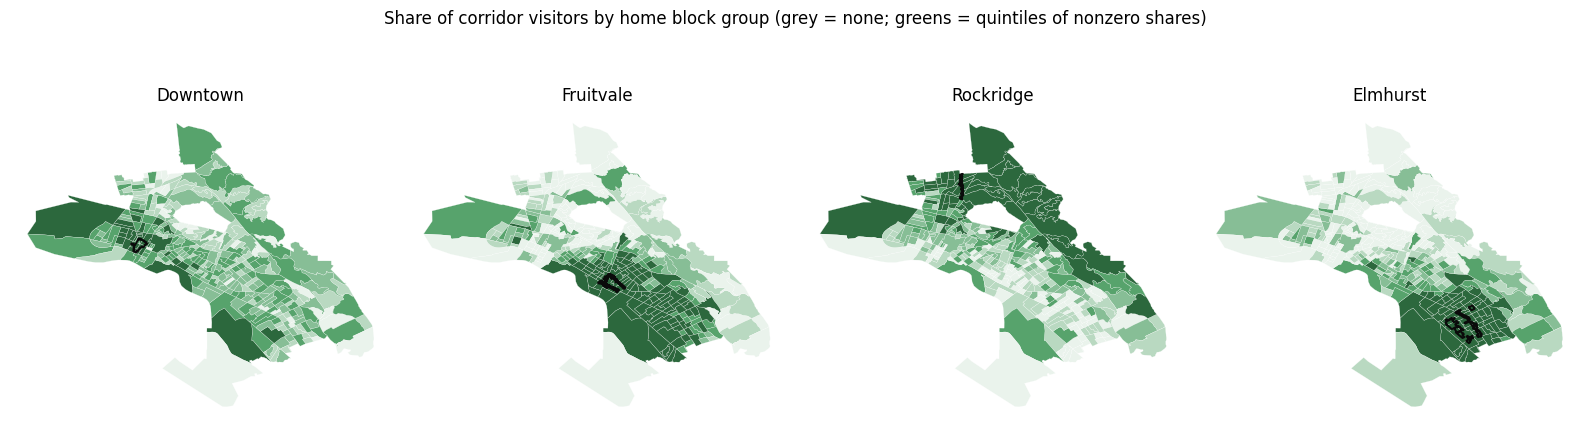

In [13]:
oak_bg = gpd.read_file(OAK_BG_GEOJSON)[["GEOID", "geometry"]]
corr_polys = gpd.read_file(SRC_DATA / "OAK_CORRIDORS.geo.json")
corr_polys["slug"] = corr_polys.corridor_name.str.replace("\xa0", " ").str.strip().str.lower().str.replace("&", "and").str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_")

breaks = legend_breaks["pooled"]["all"]
ramp = ["#EAF3EC", "#B9D9C1", "#87BE96", "#57A36C", "#2C683D"]   # same green ramp as LayerConfig.js


def color_for(v):
    if v is None or v <= 0:
        return "#cbcbcb"
    return ramp[int(np.searchsorted(breaks, v, side="right"))]


sample = ["downtown", "fruitvale", "rockridge", "elmhurst"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
for ax, slug in zip(axes, sample):
    rec = records[slug]
    oak_bg["fill"] = oak_bg.GEOID.map(lambda g: color_for(rec.get(g, {}).get("all")))
    oak_bg.plot(ax=ax, color=oak_bg.fill, edgecolor="white", linewidth=0.15)
    corr_polys[corr_polys.slug == slug].plot(ax=ax, facecolor="none", edgecolor="#0b0b0b", linewidth=1.4)
    ax.set_title(slug.replace("_", " ").title())
    ax.set_axis_off()
    ax.set_aspect("equal")
plt.suptitle("Share of corridor visitors by home block group (grey = none; greens = quintiles of nonzero shares)", y=1.02)
plt.tight_layout()
plt.show()

## Summary

- 21 per-corridor JSON files in `src/data/activity/corridor_home_origin/`, loaded lazily on corridor select.
  Shares are an equal-weight average of S1 (2019-2022) and S3 (2023H2-2025) within-segment shares; S2 is excluded.
  The same files for each segment alone are in `corridor_home_origin_s1/` and `corridor_home_origin_s3/`, so the front end
  can offer "2019-22", "2023-25" and "all years" views. The two segments are not calibrated to each other.
- `legend_breaks.json` has the quintile breaks per period for each variant (`pooled`, `S1`, `S3`). The current `breaks` in `LayerConfig.js`'s Activity
  group are placeholders; replace them with the values printed above.
- Per-segment shares (`*_by_segment`) and pooled shares in `data/activity/processed/` feed
  `04_cross_segment_comparability.ipynb`, `05_corridor_metrics.ipynb` and the explore notebooks.